In [1]:
import numpy as np
from tensorflow import keras 
import matplotlib.pyplot as plt 

In [2]:
data = np.load('mnist.npz')

In [3]:
data

NpzFile 'mnist.npz' with keys: x_test, x_train, y_train, y_test

In [4]:
x_train , y_train  = data['x_train'] , data['y_train']

In [5]:
x_train.shape

(60000, 28, 28)

In [6]:
y_train.shape

(60000,)

In [7]:
x_test , y_test = data['x_test'] , data['y_test']

In [8]:
x_test.shape

(10000, 28, 28)

In [9]:
y_test.shape

(10000,)

In [10]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

In [16]:
print(x_train.dtype)
print(x_train.min())
print(x_train.max())
print(x_train[0].shape)

float32
0.0
1.0
(28, 28)


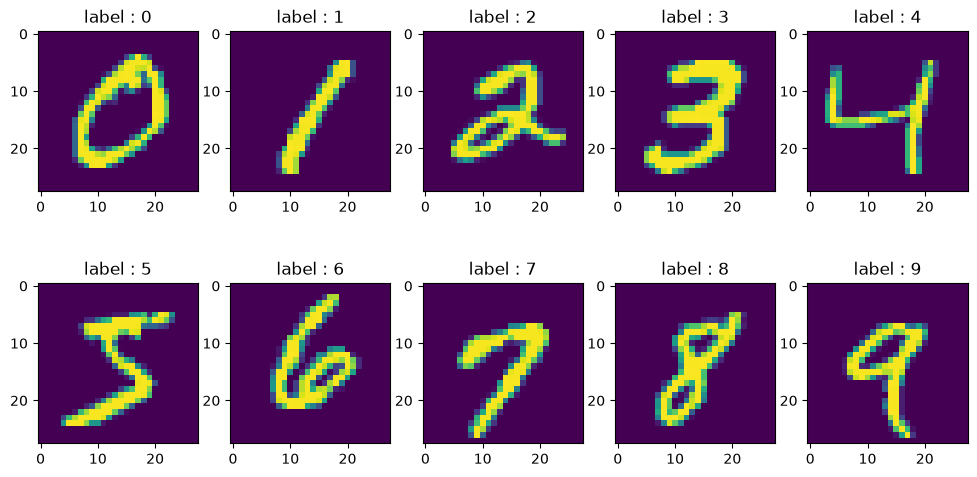

In [18]:
plt.figure(figsize=(12 , 6))
for i in range(10):
    index = np.where(y_train.flatten() == i)[0][0]
    plt.subplot(2 , 5 , i + 1)
    plt.imshow(x_train[index])
    plt.title(f"label : {i}")


In [35]:
model = keras.Sequential([
    keras.Input(shape=(28 , 28)),
    keras.layers.Flatten(),
    keras.layers.Dense(512 , activation='relu'),
    keras.layers.Dense(256 , activation='relu'),
    keras.layers.Dense(128 , activation='relu'),
    keras.layers.Dense(10 , activation='softmax'),
])

# for cnn
# model = keras.Sequential([
#     keras.Input(shape=(28 , 28 , 1)),
#     keras.layers.Conv2D(28 , (3 , 3)),
#     keras.layers.MaxPooling2D((2 , 2)),
#     keras.layers.Flatten(),
#     keras.layers.Dense(64 , activation='relu'),
#     keras.layers.Dropout(0.2),
#     keras.layers.Dense(10 , activation="softmax")
# ])

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)                    │ (None, 26, 26, 28)          │             280 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 13, 13, 28)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_3 (Flatten)                  │ (None, 4732)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 64)                  │         302,912 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_10 (Dense)                     │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 303,842 (1.16 MB)

 Trainable params: 303,842 (1.16 MB)

 Non-trainable params: 0 (0.00 B)

In [36]:
model.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.01),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [37]:
es = keras.callbacks.EarlyStopping(
    patience=3,
    monitor="val_loss",
    restore_best_weights=True
)

model.fit(
    x_train , y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    callbacks=[es]
)

Epoch 1/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8206 - loss: 0.6191 - val_accuracy: 0.9256 - val_loss: 0.2574
Epoch 2/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9117 - loss: 0.2959 - val_accuracy: 0.9407 - val_loss: 0.2048
Epoch 3/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9276 - loss: 0.2412 - val_accuracy: 0.9523 - val_loss: 0.1697
Epoch 4/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9359 - loss: 0.2123 - val_accuracy: 0.9563 - val_loss: 0.1538
Epoch 5/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9412 - loss: 0.1931 - val_accuracy: 0.9599 - val_loss: 0.1394
Epoch 6/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9462 - loss: 0.1796 - val_accuracy: 0.9607 - val_loss: 0.1333
Epoch 7/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9504 - loss: 0.1669 - val_accuracy: 0.9625 - val_loss: 0.1235
Epoch 8/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9525 - loss: 0.1561 - 

In [38]:
loss , acc = model.evaluate(x_test , y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9756 - loss: 0.0784


In [39]:
print(acc)

0.975600004196167


In [40]:
index = 12 

prediction = model.predict(x_test[index:index + 1])
predicted_class = np.argmax(prediction[0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step


Predicted class: 9
Actual class: 9


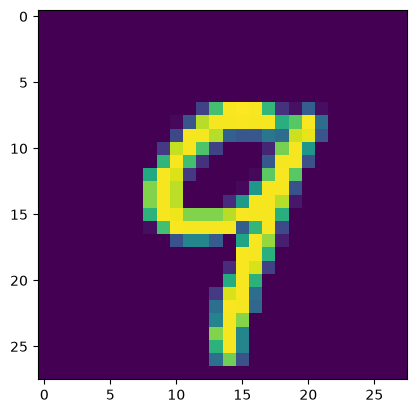

In [41]:
print("Predicted class:", predicted_class)
print("Actual class:", y_test[index])
plt.imshow(x_test[index])